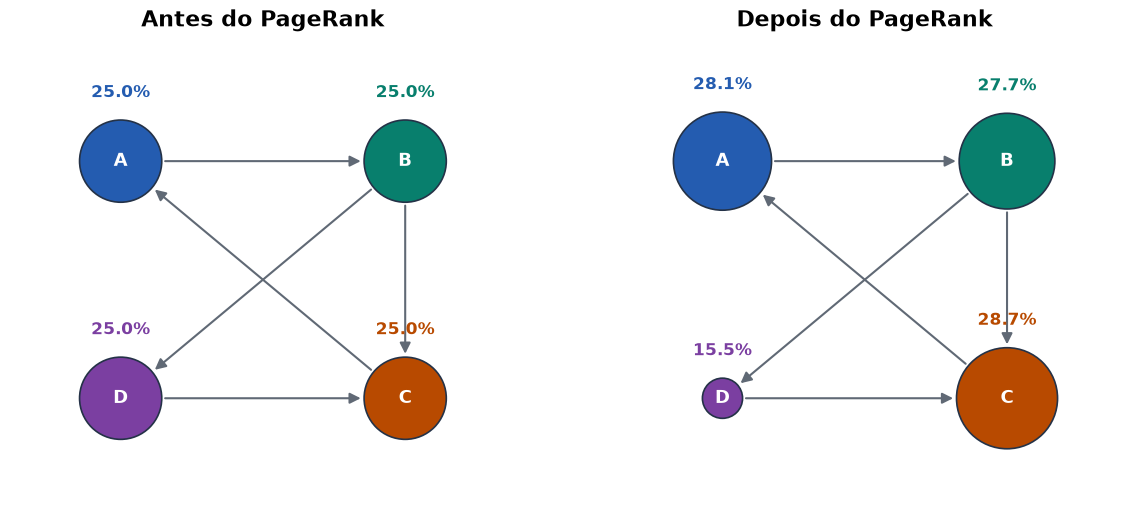

PageRank final:
C    0.2869
A    0.2814
B    0.2767
D    0.1551
dtype: float64


In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

arestas = pd.DataFrame(
    [
        ("A", "B"),
        ("B", "C"),
        ("B", "D"),
        ("C", "A"),
        ("D", "C"),
    ],
    columns=["origem", "destino"],
)

posicoes = {
    "A": (0, 1.5),
    "B": (1.8, 1.5),
    "C": (1.8, 0),
    "D": (0, 0),
}

cores = {
    "A": "#245CB0",
    "B": "#087F6D",
    "C": "#B84A00",
    "D": "#7B3FA1",
}

vertices = pd.Index(posicoes.keys())
n = len(vertices)

adjacencia = pd.crosstab(
    arestas["origem"],
    arestas["destino"],
)

adjacencia = adjacencia.reindex(
    index=vertices,
    columns=vertices,
    fill_value=0,
)

saidas = adjacencia.sum(axis=1)

P = adjacencia.div(
    saidas.where(saidas > 0),
    axis=0,
).fillna(1 / n)

alpha = 0.85

r_inicial = pd.Series(1 / n, index=vertices)
r = r_inicial.copy()

for _ in range(1000):
    r_novo = alpha * (P.T @ r) + (1 - alpha) * r_inicial

    erro = (r_novo - r).abs().sum()
    r = r_novo

    if erro < 1e-12:
        break

fig, eixos = plt.subplots(
    1, 2,
    figsize=(12, 5),
    layout="constrained",
)

paineis = [
    ("Antes do PageRank", r_inicial),
    ("Depois do PageRank", r),
]

for ax, (titulo, pontuacoes) in zip(eixos, paineis):

    circulos = {}

    for vertice, (x, y) in posicoes.items():

        razao = pontuacoes[vertice] / r_inicial[vertice]
        raio = 0.26 * razao ** 1.5

        circulo = Circle(
            (x, y),
            raio,
            facecolor=cores[vertice],
            edgecolor="#243247",
            linewidth=1.2,
            zorder=2,
        )

        circulos[vertice] = circulo
        ax.add_patch(circulo)

        ax.text(
            x, y,
            vertice,
            ha="center",
            va="center",
            color="white",
            fontsize=13,
            weight="bold",
            zorder=3,
        )

        ax.text(
            x,
            y + raio + 0.12,
            f"{pontuacoes[vertice]:.1%}",
            ha="center",
            va="bottom",
            fontsize=12,
            weight="bold",
            color=cores[vertice],
            zorder=4,
        )

    for origem, destino in arestas.itertuples(
        index=False, name=None
    ):

        seta = FancyArrowPatch(
            posicoes[origem],
            posicoes[destino],
            patchA=circulos[origem],
            patchB=circulos[destino],
            arrowstyle="-|>",
            mutation_scale=16,
            linewidth=1.5,
            color="#606975",
            zorder=1,
        )

        ax.add_patch(seta)

    ax.set_xlim(-0.7, 2.5)
    ax.set_ylim(-0.65, 2.3)
    ax.set_aspect("equal")
    ax.set_title(titulo, fontsize=16, weight="bold")
    ax.set_axis_off()

fig.savefig(
    "pagerank_antes_depois.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "pagerank_antes_depois.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("PageRank final:")
print(r.sort_values(ascending=False).round(4))

